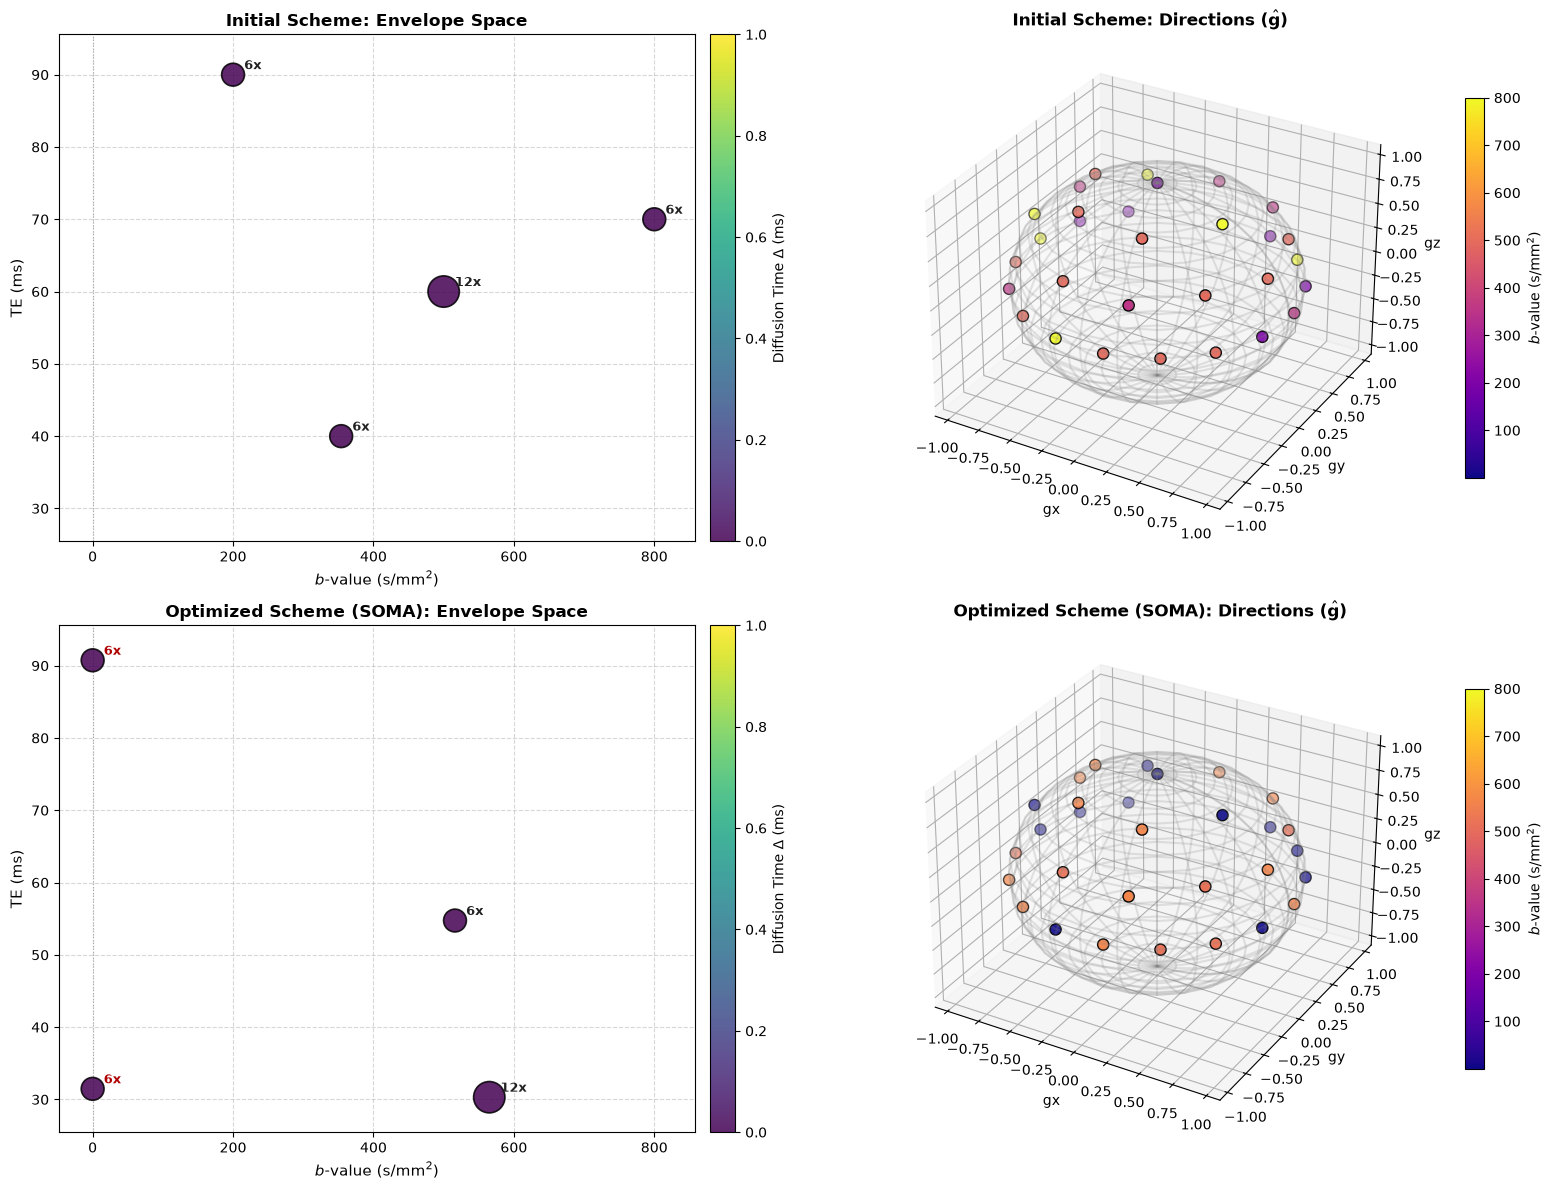


=== Optimized Shells (Excluding Fixed Baseline b0) ===
b ≈    0 s/mm² | Directions: 12 | TE: [31.5, 90.7] ms | Δ: [0.0, 0.0] ms
b ≈  520 s/mm² | Directions:  6 | TE: [54.7, 54.7] ms | Δ: [0.0, 0.0] ms
b ≈  560 s/mm² | Directions:  6 | TE: [30.3, 30.3] ms | Δ: [0.0, 0.0] ms
b ≈  570 s/mm² | Directions:  6 | TE: [30.3, 30.3] ms | Δ: [0.0, 0.0] ms


In [35]:
from pathlib import Path
import pickle
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np


def extract_scheme_parameters(scheme):
    """Extracts b-values, echo times, diffusion times, and gradient vectors
    from a MICROtool AcquisitionScheme.
    """
    if hasattr(scheme, "b_values"):
        b_vals = np.asarray(scheme.b_values).flatten()
    elif hasattr(scheme, "bvalues"):
        b_vals = np.asarray(scheme.bvalues).flatten()
    else:
        raise AttributeError("No b_values found on scheme.")

    if np.nanmax(b_vals) > 50000:
        b_vals = b_vals / 1e6

    if hasattr(scheme, "echo_times"):
        te_vals = np.asarray(scheme.echo_times).flatten()
    elif hasattr(scheme, "te"):
        te_vals = np.asarray(scheme.te).flatten()
    else:
        te_vals = np.zeros_like(b_vals)

    if np.nanmax(te_vals) < 5.0 and np.any(te_vals > 0):
        te_vals = te_vals * 1e3

    if hasattr(scheme, "delta") and scheme.delta is not None:
        delta_vals = np.asarray(scheme.delta).flatten()
    elif hasattr(scheme, "diffusion_time") and scheme.diffusion_time is not None:
        delta_vals = np.asarray(scheme.diffusion_time).flatten()
    else:
        delta_vals = np.zeros_like(b_vals)

    if np.nanmax(delta_vals) < 5.0 and np.any(delta_vals > 0):
        delta_vals = delta_vals * 1e3

    if hasattr(scheme, "b_vectors"):
        b_vecs = np.asarray(scheme.b_vectors)
    elif hasattr(scheme, "theta") and hasattr(scheme, "phi"):
        th = np.asarray(scheme.theta).flatten()
        ph = np.asarray(scheme.phi).flatten()
        b_vecs = np.column_stack(
            [np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)]
        )
    else:
        b_vecs = np.zeros((len(b_vals), 3))
        b_vecs[:, 2] = 1.0

    if hasattr(scheme, "theta") and hasattr(scheme, "phi"):
        th = np.asarray(scheme.theta).flatten()
        ph = np.asarray(scheme.phi).flatten()
        unit_dirs = np.column_stack(
            [np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)]
        )
    else:
        norms = np.linalg.norm(b_vecs, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        unit_dirs = b_vecs / norms

    return b_vals, te_vals, delta_vals, b_vecs, unit_dirs


def aggregate_envelope_points(
    b, te, delta, b_tol=50.0, te_tol=2.0, delta_tol=2.0, base_size=70, scale_factor=40
):
    """
    Groups points using wider user-defined tolerance bins:
      - b_tol:      b-values clustered within this window (e.g., 50 s/mm²)
      - te_tol:     TE values clustered within this window (e.g., 2.0 ms)
      - delta_tol:  Delta values clustered within this window (e.g., 2.0 ms)
    """
    # Discretize into coarse grid bins
    b_bins = np.round(b / b_tol) * b_tol
    te_bins = np.round(te / te_tol) * te_tol
    delta_bins = np.round(delta / delta_tol) * delta_tol

    coords = np.column_stack([b_bins, te_bins, delta_bins])
    unique_coords, inverse_indices, counts = np.unique(
        coords, axis=0, return_inverse=True, return_counts=True
    )

    # Compute mean position of each cluster for plotting accuracy
    n_clusters = len(unique_coords)
    agg_b = np.zeros(n_clusters)
    agg_te = np.zeros(n_clusters)
    agg_delta = np.zeros(n_clusters)

    for i in range(n_clusters):
        mask = (inverse_indices == i)
        agg_b[i] = np.mean(b[mask])
        agg_te[i] = np.mean(te[mask])
        agg_delta[i] = np.mean(delta[mask])

    agg_sizes = base_size + (counts - 1) * scale_factor

    return agg_b, agg_te, agg_delta, agg_sizes, counts


# -------------------------------------------------------------
# 1. Load Schemes
# -------------------------------------------------------------
schemedir = Path(
    "/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_T2/Shell_5/schemes"
)

if not (schemedir / "optimal_scheme.pkl").exists():
    matches = list(Path.cwd().rglob("optimal_scheme.pkl"))
    if matches:
        schemedir = matches[0].parent

with open(schemedir / "initial_scheme.pkl", "rb") as f:
    initial_scheme = pickle.load(f)

with open(schemedir / "optimal_scheme.pkl", "rb") as f:
    optimal_scheme_SOMA = pickle.load(f)

b_init, te_init, d_init, _, udirs_init = extract_scheme_parameters(initial_scheme)
b_opt, te_opt, d_opt, _, udirs_opt = extract_scheme_parameters(optimal_scheme_SOMA)

# -------------------------------------------------------------
# 2. Filter Both Schemes Using Initial Scheme's Baseline Mask
# -------------------------------------------------------------
keep_mask = b_init > 1e-2

b_init_f = b_init[keep_mask]
te_init_f = te_init[keep_mask]
d_init_f = d_init[keep_mask]
udirs_init_f = udirs_init[keep_mask]

b_opt_f = b_opt[keep_mask]
te_opt_f = te_opt[keep_mask]
d_opt_f = d_opt[keep_mask]
udirs_opt_f = udirs_opt[keep_mask]

# Aggregate with the wider clustering tolerance
agg_b_init, agg_te_init, agg_d_init, sizes_init, counts_init = (
    aggregate_envelope_points(b_init_f, te_init_f, d_init_f)
)
agg_b_opt, agg_te_opt, agg_d_opt, sizes_opt, counts_opt = (
    aggregate_envelope_points(b_opt_f, te_opt_f, d_opt_f)
)

# -------------------------------------------------------------
# 3. Dynamic Normalization & Shared Axis Limits
# -------------------------------------------------------------
d_all = np.concatenate([d_init_f, d_opt_f])
vmin_delta = float(np.nanmin(d_all))
vmax_delta = float(np.nanmax(d_all))
if np.isclose(vmin_delta, vmax_delta):
    vmax_delta = vmin_delta + 1.0
delta_norm = mcolors.Normalize(vmin=vmin_delta, vmax=vmax_delta)

b_all = np.concatenate([b_init_f, b_opt_f])
min_b = float(np.nanmin(b_all))
max_b = float(np.nanmax(b_all))
if np.isclose(min_b, max_b):
    max_b = min_b + 100.0

b_norm = mcolors.Normalize(vmin=max(0.0, min_b), vmax=max_b)

b_margin = max(40.0, 0.06 * (max_b - min_b))
xlim_shared = (-b_margin, max_b + b_margin * 1.2)

te_all = np.concatenate([te_init_f, te_opt_f])
te_min, te_max = float(np.nanmin(te_all)), float(np.nanmax(te_all))
te_margin = 0.08 * (te_max - te_min) if not np.isclose(te_min, te_max) else 6.0
ylim_shared = (max(0, te_min - te_margin), te_max + te_margin)

# -------------------------------------------------------------
# 4. Render Figure (2x2)
# -------------------------------------------------------------
fig = plt.figure(figsize=(16, 12))

# Unit sphere mesh
u = np.linspace(0, 2 * np.pi, 25)
v = np.linspace(0, np.pi, 25)
sphere_x = np.outer(np.cos(u), np.sin(v))
sphere_y = np.outer(np.sin(u), np.sin(v))
sphere_z = np.outer(np.ones(np.size(u)), np.cos(v))

# --- Panel 1: Initial Scheme Envelope ---
ax1 = fig.add_subplot(2, 2, 1)
sc1 = ax1.scatter(
    agg_b_init,
    agg_te_init,
    c=agg_d_init,
    cmap="viridis",
    norm=delta_norm,
    s=sizes_init,
    edgecolors="k",
    linewidths=1.2,
    alpha=0.85,
    zorder=3,
)

for x, y, count in zip(agg_b_init, agg_te_init, counts_init):
    ax1.annotate(
        f"{count}x",
        xy=(x, y),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#222222",
        zorder=4,
    )

ax1.axvline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7, zorder=1)
ax1.set_xlim(xlim_shared)
ax1.set_ylim(ylim_shared)
ax1.set_xlabel(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=11)
ax1.set_ylabel(r"$\mathrm{TE}$ ($\mathrm{ms}$)", fontsize=11)
ax1.set_title("Initial Scheme: Envelope Space", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5, zorder=1)

cbar1 = fig.colorbar(sc1, ax=ax1, pad=0.02)
cbar1.set_label(r"Diffusion Time $\Delta$ ($\mathrm{ms}$)", fontsize=10)

# --- Panel 2: Initial Scheme Unit Gradient Directions ---
ax2 = fig.add_subplot(2, 2, 2, projection="3d")
ax2.plot_wireframe(sphere_x, sphere_y, sphere_z, color="gray", alpha=0.2)
sc2 = ax2.scatter(
    udirs_init_f[:, 0],
    udirs_init_f[:, 1],
    udirs_init_f[:, 2],
    c=b_init_f,
    cmap="plasma",
    norm=b_norm,
    s=65,
    edgecolors="k",
)
cbar2 = fig.colorbar(sc2, ax=ax2, pad=0.08, shrink=0.75)
cbar2.set_label(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=10)
ax2.set_title(
    "Initial Scheme: Directions ($\hat{\mathbf{g}}$)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlim([-1.1, 1.1])
ax2.set_ylim([-1.1, 1.1])
ax2.set_zlim([-1.1, 1.1])
ax2.set_xlabel("gx")
ax2.set_ylabel("gy")
ax2.set_zlabel("gz")

# --- Panel 3: Optimized Scheme Envelope ---
ax3 = fig.add_subplot(2, 2, 3, sharex=ax1, sharey=ax1)
sc3 = ax3.scatter(
    agg_b_opt,
    agg_te_opt,
    c=agg_d_opt,
    cmap="viridis",
    norm=delta_norm,
    s=sizes_opt,
    edgecolors="k",
    linewidths=1.2,
    alpha=0.85,
    zorder=3,
)

for x, y, count in zip(agg_b_opt, agg_te_opt, counts_opt):
    ax3.annotate(
        f"{count}x",
        xy=(x, y),
        xytext=(8, 4),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color="#b00000" if x < 10.0 else "#222222",
        zorder=4,
    )

ax3.axvline(0, color="gray", linestyle=":", linewidth=0.8, alpha=0.7, zorder=1)
ax3.set_xlim(xlim_shared)
ax3.set_ylim(ylim_shared)
ax3.set_xlabel(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=11)
ax3.set_ylabel(r"$\mathrm{TE}$ ($\mathrm{ms}$)", fontsize=11)
ax3.set_title(
    "Optimized Scheme (SOMA): Envelope Space", fontsize=12, fontweight="bold"
)
ax3.grid(True, linestyle="--", alpha=0.5, zorder=1)

cbar3 = fig.colorbar(sc3, ax=ax3, pad=0.02)
cbar3.set_label(r"Diffusion Time $\Delta$ ($\mathrm{ms}$)", fontsize=10)

# --- Panel 4: Optimized Scheme Unit Gradient Directions ---
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
ax4.plot_wireframe(sphere_x, sphere_y, sphere_z, color="gray", alpha=0.2)
sc4 = ax4.scatter(
    udirs_opt_f[:, 0],
    udirs_opt_f[:, 1],
    udirs_opt_f[:, 2],
    c=b_opt_f,
    cmap="plasma",
    norm=b_norm,
    s=65,
    edgecolors="k",
)
cbar4 = fig.colorbar(sc4, ax=ax4, pad=0.08, shrink=0.75)
cbar4.set_label(r"$b$-value ($\mathrm{s/mm}^2$)", fontsize=10)
ax4.set_title(
    "Optimized Scheme (SOMA): Directions ($\hat{\mathbf{g}}$)",
    fontsize=12,
    fontweight="bold",
)
ax4.set_xlim([-1.1, 1.1])
ax4.set_ylim([-1.1, 1.1])
ax4.set_zlim([-1.1, 1.1])
ax4.set_xlabel("gx")
ax4.set_ylabel("gy")
ax4.set_zlabel("gz")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5. Summary Breakdown
# -------------------------------------------------------------
print("\n=== Optimized Shells (Excluding Fixed Baseline b0) ===")
unique_b, counts = np.unique(np.round(b_opt_f, -1), return_counts=True)
for b_val, count in zip(unique_b, counts):
    mask = np.isclose(np.round(b_opt_f, -1), b_val)
    print(
        f"b ≈ {int(b_val):4d} s/mm² | Directions: {count:2d} | "
        f"TE: [{np.min(te_opt_f[mask]):.1f}, {np.max(te_opt_f[mask]):.1f}] ms | "
        f"Δ: [{np.min(d_opt_f[mask]):.1f}, {np.max(d_opt_f[mask]):.1f}] ms"
    )

Valid fits: initial=1000, optimal=1000

Initial scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D  0.00191  0.09186  0.09188      0.00096     0.04593      0.04594
T2       0.00006  0.00307  0.00307      0.00113     0.06147      0.06148
S0       0.00520  0.07145  0.07164      0.00520     0.07145      0.07164 
TOTAL scaled RMSE: 0.06062

Optimal scheme
             bias      std     RMSE  scaled bias  scaled std  scaled RMSE
model_D -0.00111  0.05874  0.05875     -0.00055     0.02937      0.02937
T2      -0.00008  0.00183  0.00183     -0.00167     0.03654      0.03657
S0       0.00231  0.02949  0.02958      0.00231     0.02949      0.02958 
TOTAL scaled RMSE: 0.03202

Improvement of total scaled RMSE: 47.2%


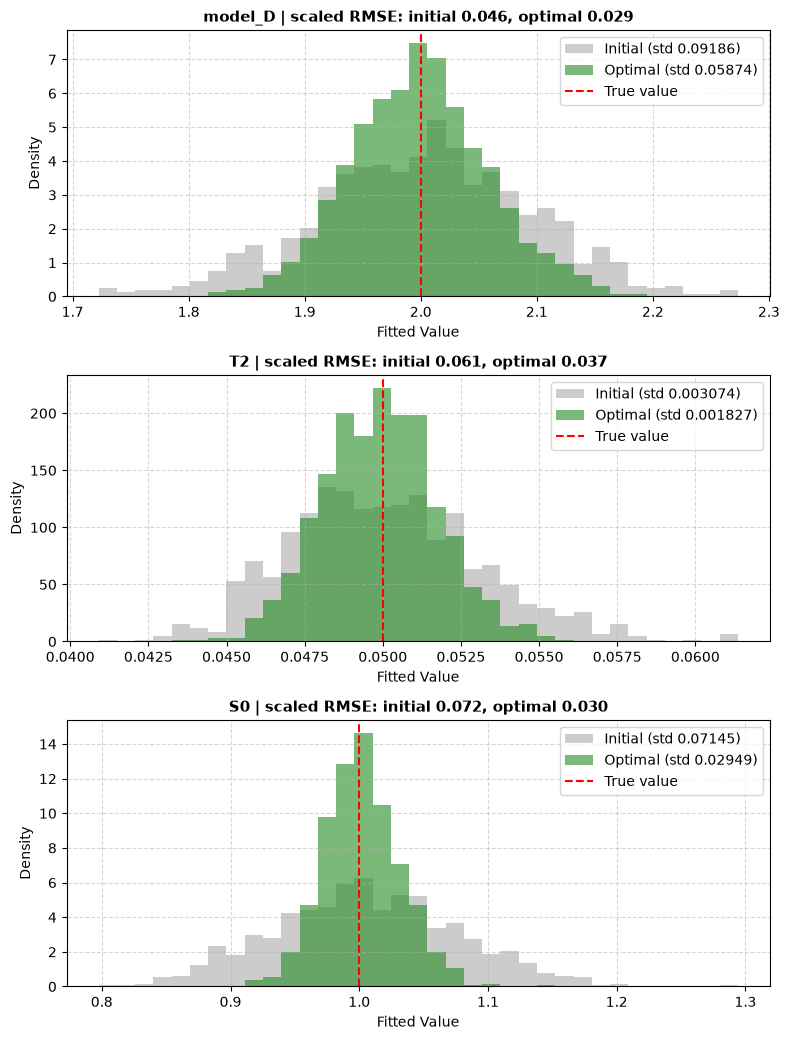

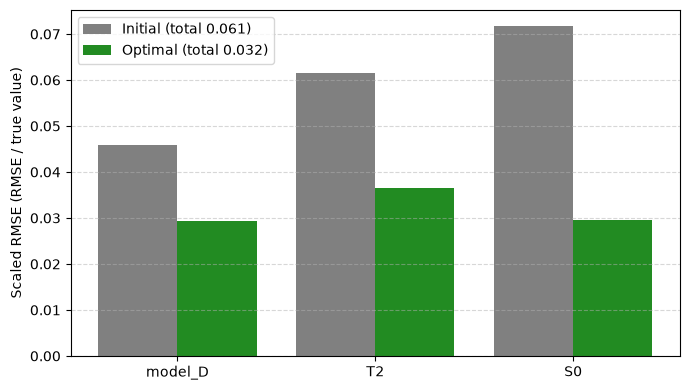

In [36]:
from pathlib import Path
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------ directories & loading
# Ensure simdir points to your simulation directory
# e.g., plotdir, modeldir, simdir, schemedir = make_expirement_directories(Path.cwd() / "Ball_T2", "Shell_3")
simdir = Path("/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_T2/Shell_5/simulations")

initial_sim_path = simdir / "initial.pkl"
optimal_sim_path = simdir / "optimal.pkl"

# Load initial simulation result
with open(initial_sim_path, "rb") as f:
  initial_sim_data = pickle.load(f)

# Extract fitted results dictionary/DataFrame depending on saved object structure
initial = getattr(initial_sim_data, "result", initial_sim_data)

# Load or retrieve optimal simulation result
if optimal_sim_path.exists():
  with open(optimal_sim_path, "rb") as f:
    optimal_sim_data = pickle.load(f)
  optimal = getattr(optimal_sim_data, "result", optimal_sim_data)
else:
  # Fallback if already running in current namespace
  optimal = simulation.result

# ------------------------------------------------------------------ data conversion
df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

# Ground truth used for the simulation (same units as the fitted columns)
true_values = {
    "model_D": 2,  # 1e-9 m²/s
    "T2": 0.050,  # seconds
    "S0": 1.0,
}
scales = dict(true_values)  # relative RMSE = RMSE / true value

common_cols = [
    c for c in df_opt.columns if c in df_init.columns and c in true_values
]
missing = [
    c for c in df_opt.columns if c in df_init.columns and c not in true_values
]
if missing:
  print(f"Skipping columns without a true value: {missing}")

# Drop failed fits (NaN / inf)
df_init = df_init[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
df_opt = df_opt[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Valid fits: initial={len(df_init)}, optimal={len(df_opt)}")


# ------------------------------------------------------------------ RMSE
def rmse_table(df):
  rows = {}
  for col in common_cols:
    err = df[col].to_numpy() - true_values[col]
    rmse = np.sqrt(np.mean(err**2))
    s = abs(scales[col])
    rows[col] = {
        "bias": err.mean(),
        "std": err.std(),
        "RMSE": rmse,
        "scaled bias": err.mean() / s,
        "scaled std": err.std() / s,
        "scaled RMSE": rmse / s,
    }
  tab = pd.DataFrame(rows).T
  total = np.sqrt(np.mean(tab["scaled RMSE"] ** 2))
  return tab, total


tab_init, total_init = rmse_table(df_init)
tab_opt, total_opt = rmse_table(df_opt)

print(
    "\nInitial scheme\n",
    tab_init.round(5),
    f"\nTOTAL scaled RMSE: {total_init:.5f}",
)
print(
    "\nOptimal scheme\n",
    tab_opt.round(5),
    f"\nTOTAL scaled RMSE: {total_opt:.5f}",
)
print(
    f"\nImprovement of total scaled RMSE: {100 * (1 - total_opt / total_init):.1f}%"
)

# ------------------------------------------------------------------ histograms
fig, axes = plt.subplots(
    nrows=len(common_cols),
    ncols=1,
    figsize=(8, 3.5 * len(common_cols)),
    squeeze=False,
)

for i, col in enumerate(common_cols):
  ax = axes[i, 0]

  # Shared bin edges so both histograms are directly comparable
  both = np.concatenate([df_init[col].to_numpy(), df_opt[col].to_numpy()])
  bins = np.linspace(both.min(), both.max(), 36)

  ax.hist(
      df_init[col],
      bins=bins,
      density=True,
      alpha=0.4,
      color="gray",
      label=f"Initial (std {tab_init.loc[col, 'std']:.4g})",
  )
  ax.hist(
      df_opt[col],
      bins=bins,
      density=True,
      alpha=0.6,
      color="forestgreen",
      label=f"Optimal (std {tab_opt.loc[col, 'std']:.4g})",
  )
  ax.axvline(true_values[col], color="red", linestyle="--", label="True value")

  ax.set_title(
      f"{col} | scaled RMSE: initial {tab_init.loc[col, 'scaled RMSE']:.3f}, "
      f"optimal {tab_opt.loc[col, 'scaled RMSE']:.3f}",
      fontsize=11,
      fontweight="bold",
  )
  ax.set_xlabel("Fitted Value")
  ax.set_ylabel("Density")
  ax.legend()
  ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------ bar plot
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(common_cols))
ax.bar(
    x - 0.2,
    tab_init["scaled RMSE"],
    0.4,
    color="gray",
    label=f"Initial (total {total_init:.3f})",
)
ax.bar(
    x + 0.2,
    tab_opt["scaled RMSE"],
    0.4,
    color="forestgreen",
    label=f"Optimal (total {total_opt:.3f})",
)
ax.set_xticks(x)
ax.set_xticklabels(common_cols)
ax.set_ylabel("Scaled RMSE (RMSE / true value)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()